# Análise do ID3 para PopOut

## Objetivos da análise
Pretendemos analisar o algoritmo ID3 por nós desenvolvido em três frentes:
- Performance preditiva num dataset simples de teste (iris)
- Performance preditiva num dataset gerado pelo MCTS para o jogo PopOut
- Capacidade para jogar PopOut contra humanos, MCTS, e outras instâncias de si mesmo

> Nota:
Todos os ficheiros referidos neste notebook encontram-se na diretório decision_tree

## Implementação do algoritmo

O ID3 (Iterative Dichotomiser 3) é um algoritmo de aprendizagem supervisionada que constrói árvores de decisão de forma recursiva. A cada passo, escolhe o atributo que melhor separa os dados com base no **Ganho de Informação** (*Information Gain*), usando a **Entropia** como medida de impureza.

### Entropia

A entropia (metrics.py -> get_enthropy) mede o grau de desordem de um conjunto de dados. Para uma variável alvo $y$ com classes $c_1, c_2, \dots, c_n$, a entropia é:

$$
H(y) = -\sum_{i=1}^{n} p_i \log_2(p_i)
$$

onde $p_i$ é a proporção de exemplos da classe $c_i$ no conjunto.
Valores próximos de $0$ indicam conjuntos puros (uma só classe); valores próximos de $\log_2(n)$ indicam máxima dispersão.

### Ganho de Informação

O Ganho de Informação (metrics.py -> calculate_information_gain) mede a redução da entropia ao particionar os dados pelo atributo $X$:

$$
IG(y, X) = H(y) - \sum_{v \in \text{vals}(X)} \frac{|y_{X=v}|}{|y|} \cdot H(y_{X=v})
$$

O algoritmo seleciona o atributo (e, no caso numérico, o ponto de corte) que maximiza $IG$.

### Tratamento de atributos numéricos

O código testa pontos de corte a meio dos valores consecutivos ordenados (id3.py > _get_best_split):

$$
\text{possible\_splits} = \frac{\text{unique\_vals}[1:] + \text{unique\_vals}[:-1]}{2}
$$

Para cada split candidato, os dados são divididos em $X \leq split$ e $X > split$, calculando-se o IG. Atributos inteiros com 4 ou menos valores únicos são tratados como categóricos (auxiliar.py -> is_numeric).

### Critérios de paragem

A construção recursiva da árvore termina quando:

- O conjunto de dados está vazio (todas as *features* foram usadas);
- A profundidade máxima (`max_depth`) é atingida;
- O número de amostras é inferior a `min_samples`.

Nestes casos, o nó torna-se folha e devolve a classe maioritária do subconjunto.

### Previsão para o jogo PopOut

O método `predict_valid()` foi adaptado para o cenário de jogo: percorre a árvore até uma folha e, se a classe prevista não for uma jogada válida, sobe na árvore até encontrar um nó cuja classe maioritária seja válida. Se nenhum nó tiver uma classe válida, escolhe aleatoriamente.

### Parâmetros

| Parâmetro | Descrição |
|-----------|-----------|
| `max_depth` | Profundidade máxima da árvore (se igual a None, não existe profundidade máxima) |
| `min_samples` | Número mínimo de amostras para continuar a dividir |

## 1 - Performance preditiva no dataset iris
O principal objetivo deste teste é verificar o correto funcionamento do algoritmo, visto tratar-se de um dataset bastante simples

In [34]:
%load_ext autoreload
%autoreload 2

import sys
import os
from pathlib import Path
sys.path.append(os.path.abspath(".."))

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:
df = pd.read_csv(Path("..", "data", "iris.csv"))
df.head()

,ID,sepallength,sepalwidth,petallength,petalwidth,class
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [36]:
X = df.drop("class", axis=1)
y=df["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [37]:
from decision_tree import id3
tree = id3.ID3() #no arguments, min_samples=10 and max_depth=None
tree.fit(X_train, y_train)

In [38]:
y_pred = tree.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))
#o carlos soares deve-nos um jantar

Accuracy:  1.0


O modelo acertou em todos os (50) casos de teste. Dado o tamanho reduzido do dataset e a sua simplicidade isto não constitui uma grande surpresa.

In [39]:
tree.print_tree()

└─ Root  --->  [Split: Feature ID]
    └─ If Feature ID < 100.50  --->  [Split: Feature petallength]
        └─ If Feature petallength < 2.45  --->  Predict: Iris-setosa
        └─ If Feature petallength >= 2.45  --->  Predict: Iris-versicolor
    └─ If Feature ID >= 100.50  --->  Predict: Iris-virginica


Podemos ver que, apesar de não limitarmos a profundidade máxima da árvore, a sua complexidade não é muito elevada.

## 2 - Performance preditiva no dataset PopOut

O dataset MCTS (`data/dataset_mcts.csv`) foi gerado pelo MCTS durante partidas de PopOut. Contém ~21k estados de jogo, cada um representado por 42 features (`pos_0` a `pos_41`), correspondentes às posições do tabuleiro 6×7 (valores -1, 0, 1 para peças do oponente, vazio, peças do agente). O target é a `move` (coluna onde jogar, 0–13).

### Processo de treino

As árvores foram treinadas com o script `scripts/train_id3.py`, seguindo os passos:

- Split 90/10 treino-teste com `random_state=42`;
- Grid search sobre hiperparâmetros:
   - `max_depth ∈ {None, 5, 10, 50, 100}`
   - `min_samples ∈ {1, 2, 5, 10, 20, 50}`
- 30 árvores treinadas com `ID3().fit()` e guardadas em `decision_tree/pre_trained_trees/`;
- *Accuracy* calculada com `accuracy_score(y_test, y_pred)` para cada combinação.

Os resultados foram registados no ficheiro `job_1281207.out`.

In [40]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df = pd.read_csv(Path("..", "data", "dataset_mcts.csv"))
print("Dimensão:", df.shape)
df.head()

Dimensão: (21110, 43)


,pos_0,pos_1,pos_2,pos_3,pos_4,pos_5,pos_6,pos_7,pos_8,pos_9,...,pos_33,pos_34,pos_35,pos_36,pos_37,pos_38,pos_39,pos_40,pos_41,move
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,3


In [42]:
print("Distribuição dos targets:")
print(df["move"].value_counts().sort_index())
print(f"\nNúmero de classes: {df['move'].nunique()}")
print(f"Baseline aleatório: {1/df['move'].nunique():.1%}")

Distribuição dos targets:
move
0     1411
1     2738
2     3662
3     3783
4     3617
5     2590
6     1255
7       97
8      297
9      415
10     476
11     431
12     258
13      80
Name: count, dtype: int64

Número de classes: 14
Baseline aleatório: 7.1%


In [43]:
# Resultados extraídos do job_1281207.out
# 50 de profundidade corresponde a None (sem limite de profundidade), uma vez que o máximo de profundidade de uma árvore é 42 (nº de features)
# Para facilitar a representação gráfica convertemos para um inteiro
results = [
    (50, 1, 0.32780672666982474),
    (50, 5, 0.3192799621032686),
    (50, 10, 0.324964471814306),
    (50, 20, 0.3410705826622454),
    (50, 50, 0.3481762198010422),
    (50, 100, 0.33443865466603506),
    (5, 1, 0.33728090952155376),
    (5, 5, 0.33728090952155376),
    (5, 10, 0.3377546186641402),
    (5, 20, 0.3387020369493131),
    (5, 50, 0.3415442918048318),
    (5, 100, 0.32780672666982474),
    (10, 1, 0.324964471814306),
    (10, 5, 0.319753671245855),
    (10, 10, 0.32354334438654664),
    (10, 20, 0.3410705826622454),
    (10, 50, 0.3481762198010422),
    (10, 100, 0.33443865466603506),
    (20, 1, 0.32780672666982474),
    (20, 5, 0.3192799621032686),
    (20, 10, 0.324964471814306),
    (20, 20, 0.3410705826622454),
    (20, 50, 0.3481762198010422),
    (20, 100, 0.33443865466603506),
    (30, 1, 0.32780672666982474),
    (30, 5, 0.3192799621032686),
    (30, 10, 0.324964471814306),
    (30, 20, 0.3410705826622454),
    (30, 50, 0.3481762198010422),
    (30, 100, 0.33443865466603506),
]

df_results = pd.DataFrame(results, columns=["max_depth", "min_samples", "accuracy"])
#df_results["max_depth"] = df_results["max_depth"].apply(lambda x: "None" if x is None else str(x))
df_results_sorted = df_results.sort_values("accuracy", ascending=False).reset_index(drop=True)
df_results["accuracy"] = df_results["accuracy"].apply(lambda x: f"{x:.2%}")
df_results_sorted

,max_depth,min_samples,accuracy
0,10,50,0.348176
1,30,50,0.348176
2,50,50,0.348176
3,20,50,0.348176
4,5,50,0.341544
5,10,20,0.341071
6,50,20,0.341071
7,30,20,0.341071
8,20,20,0.341071
9,5,20,0.338702


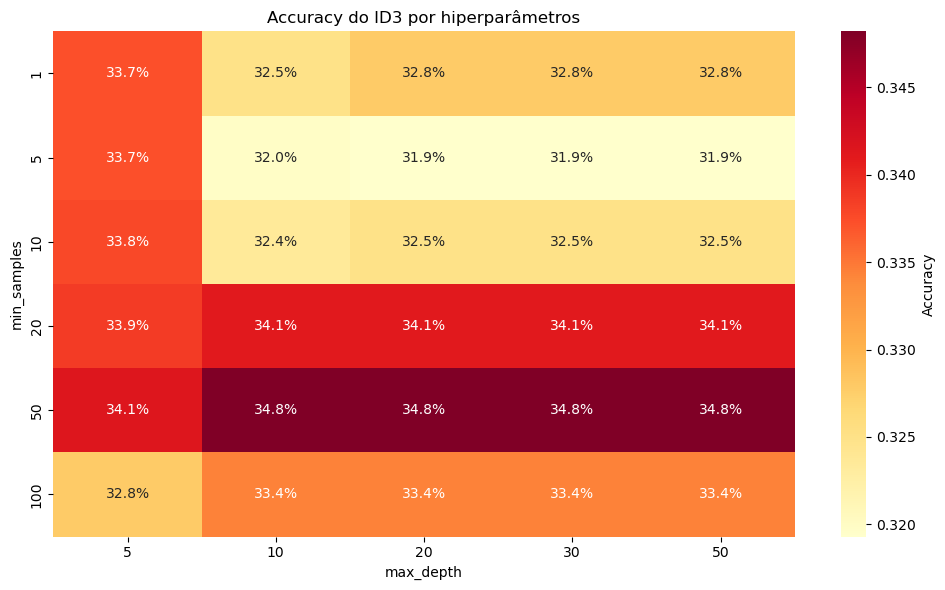

In [44]:
# Heatmap: max_depth vs min_samples
pivot = df_results.copy()
pivot["accuracy"] = pivot["accuracy"].str.rstrip("%").astype(float) / 100
pivot = pivot.pivot_table(
    values="accuracy",
    index="min_samples",
    columns="max_depth",
    aggfunc="first"
)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".1%", cmap="YlOrRd", cbar_kws={"label": "Accuracy"})
plt.title("Accuracy do ID3 por hiperparâmetros")
plt.ylabel("min_samples")
plt.xlabel("max_depth")
plt.tight_layout()
plt.show()

### Discussão

A melhor combinação atinge ~34.8% de accuracy, o que é cerca de 5× melhor que o baseline aleatório de ~7.1% (14 classes).

Observações:
- `max_depth` acima de 10 não traz melhorias significativas — o dataset pode não requerer árvores muito profundas para capturar os padrões relevantes.
- `min_samples` = 50 parece ser o melhor valor para todas as profundidades; `min_samples` = 100 já regulariza demais e reduz a accuracy.
- Os resultados são consistentes entre `max_depth` = None, 20 e 30 para o mesmo `min_samples`, indicando que a árvore raramente ultrapassa a profundidade 20.

Note-se que a accuracy padrão (acertar na coluna exata) é uma métrica exigente. No ponto 3, o método `predict_valid` mitiga este problema ao subir na árvore até encontrar uma jogada válida, tornando o modelo mais robusto para o contexto do jogo.

## 3 - Performance no jogo PopOut

Nesta secção colocamos as árvores ID3 pré-treinadas a jogar umas contra as outras, contra um jogador aleatório e contra um MCTS. O objetivo é verificar se a accuracy preditiva se traduz em melhor performance no jogo real.

Cada jogada é escolhida pelo método `predict_valid`, que percorre a árvore até encontrar uma jogada legal. Caso nenhum nó na árvore retorne uma jogada válida, escolhe aleatoriamente.

O torneio segue o formato round-robin com ambas as ordens (A vs B e B vs A) para cancelar a vantagem do primeiro jogador.

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import load

from game.game import Game
from game.players import MCTS
from game.data_storage import move_dict

np.random.seed(42)

In [46]:
rev_move_dict = {v: k for k, v in move_dict.items()}

def make_id3_player(tree, name):
    """Creates a player function from a loaded ID3 tree."""
    def id3_move(board, player):
        flat = np.empty(42, dtype=int)
        idx = 0
        for col in board.b:
            for piece in col:
                flat[idx] = piece * player
                idx += 1

        valid_ids = []
        for col in range(board.cols):
            if board.is_valid_move("drop", col, player):
                valid_ids.append(move_dict[f"drop_{col + 1}"])
            if board.is_valid_move("pop", col, player):
                valid_ids.append(move_dict[f"pop_{col + 1}"])

        pred_id = tree.predict_valid(flat, valid_ids)
        move_str = rev_move_dict[pred_id]
        move_type, move_col_str = move_str.split("_")
        move_col = int(move_col_str) - 1
        board.apply_move(move_type, move_col, player)

    id3_move.__name__ = name
    return id3_move


def random_move(board, player):
    """Picks a random valid move."""
    import random
    moves = board.possible_moves(player)
    chosen = random.choice(moves)
    board.apply_move(chosen[0], chosen[1], player)

In [47]:
def variants_stats(variants, n_games=5):
    """Run pairwise matches between variants. Each pair tested in both orders.
    Variants is a list of (name, callable, instance_or_None).
    """
    stats = {}
    for name, _, _ in variants:
        stats[name] = {
            "wins": 0,
            "draws": 0,
            "losses": 0,
            "avg_time_sum": 0.0,
        }

    for i in range(len(variants)):
        for j in range(i + 1, len(variants)):
            ordered_pairs = [
                (variants[i], variants[j]),
                (variants[j], variants[i]),
            ]

            for (p1_name, p1_move, p1_inst), (p2_name, p2_move, p2_inst) in ordered_pairs:
                for _ in range(n_games):
                    if p1_inst is not None:
                        p1_inst.root = None
                    if p2_inst is not None:
                        p2_inst.root = None

                    result = Game("", "").notebook_run(
                        p1_name,
                        p1_move,
                        p2_name,
                        p2_move,
                    )

                    stats[p1_name]["avg_time_sum"] += result["avg_time_player1"]
                    stats[p2_name]["avg_time_sum"] += result["avg_time_player2"]

                    if result["winner"] == 1:
                        stats[p1_name]["wins"] += 1
                        stats[p2_name]["losses"] += 1
                    elif result["winner"] == -1:
                        stats[p2_name]["wins"] += 1
                        stats[p1_name]["losses"] += 1
                    else:
                        stats[p1_name]["draws"] += 1
                        stats[p2_name]["draws"] += 1

    for name in stats:
        total = stats[name]["wins"] + stats[name]["draws"] + stats[name]["losses"]
        stats[name]["total_games"] = total
        stats[name]["win_rate"] = stats[name]["wins"] / total if total else 0
        stats[name]["draw_rate"] = stats[name]["draws"] / total if total else 0
        stats[name]["loss_rate"] = stats[name]["losses"] / total if total else 0
        stats[name]["score"] = (stats[name]["wins"] + 0.5 * stats[name]["draws"]) / total if total else 0
        stats[name]["avg_time_per_move"] = stats[name]["avg_time_sum"] / total if total else 0

    return stats


def stats_dataframe(stats):
    """Convert the stats dictionary into a sorted dataframe."""
    df = pd.DataFrame.from_dict(stats, orient="index")
    cols = [
        "wins",
        "draws",
        "losses",
        "total_games",
        "win_rate",
        "draw_rate",
        "loss_rate",
        "score",
        "avg_time_per_move",
    ]
    return df[cols].sort_values(["score", "avg_time_per_move"], ascending=[False, True])


def plot_bars_for_each_var(stats, title):
    variants = list(stats.keys())
    measurements = [
        ("Wins", [stats[v]["wins"] for v in variants], "#2ca02c"),
        ("Draws", [stats[v]["draws"] for v in variants], "#ff7f0e"),
        ("Losses", [stats[v]["losses"] for v in variants], "#d62728"),
    ]

    x = np.arange(len(variants))
    width = 0.22

    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
    for idx, (label, values, color) in enumerate(measurements):
        rects = ax.bar(x + width * idx, values, width, label=label, color=color)
        ax.bar_label(rects, padding=3)

    ax.set_ylabel("Número de jogos")
    ax.set_title(title)
    ax.set_xticks(x + width, variants, rotation=35, ha="right")
    ax.legend(loc="upper right", ncols=3)
    plt.show()


def plot_score_vs_time(stats, title):
    names = list(stats.keys())
    times = [stats[name]["avg_time_per_move"] for name in names]
    scores = [stats[name]["score"] for name in names]

    plt.figure(figsize=(8, 5))
    plt.scatter(times, scores)

    for name, x, y in zip(names, times, scores):
        plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))

    plt.xlabel("Tempo médio por jogada (s)")
    plt.ylabel("Score")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

In [48]:
# Load ID3 trees (5 combos representative of the accuracy range)
trees_dir = Path("..", "decision_tree", "pre_trained_trees")

tree_none_50  = load(trees_dir / "treeNone_50.joblib")
tree_5_50     = load(trees_dir / "tree5_50.joblib")
tree_10_50    = load(trees_dir / "tree10_50.joblib")
tree_none_100 = load(trees_dir / "treeNone_100.joblib")
tree_none_5   = load(trees_dir / "treeNone_5.joblib")

# MCTS baseline (fast: 100 iterations)
mcts_100 = MCTS(max_iter=100)

# Variants: (name, callable, instance_or_None)
variants = [
    ("id3_none_50",  make_id3_player(tree_none_50, "id3_none_50"),  None),
    ("id3_5_50",     make_id3_player(tree_5_50,    "id3_5_50"),     None),
    ("id3_10_50",    make_id3_player(tree_10_50,  "id3_10_50"),    None),
    ("id3_none_100", make_id3_player(tree_none_100,"id3_none_100"), None),
    ("id3_none_5",   make_id3_player(tree_none_5,  "id3_none_5"),   None),
    ("random",       random_move,                   None),
    ("mcts_100",     mcts_100.move,                mcts_100),
]

stats_game = variants_stats(variants, n_games=10)
print("Torneio concluído.")

Torneio concluído.


In [49]:
stats_dataframe(stats_game)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
mcts_100,83,0,37,120,0.691667,0.0,0.308333,0.691667,0.069302
id3_5_50,78,0,42,120,0.650000,0.0,0.350000,0.650000,0.000038
id3_none_5,68,0,52,120,0.566667,0.0,0.433333,0.566667,0.000050
id3_none_100,66,0,54,120,0.550000,0.0,0.450000,0.550000,0.000039
id3_10_50,63,0,57,120,0.525000,0.0,0.475000,0.525000,0.000040
id3_none_50,59,0,61,120,0.491667,0.0,0.508333,0.491667,0.000042
random,3,0,117,120,0.025000,0.0,0.975000,0.025000,0.000004


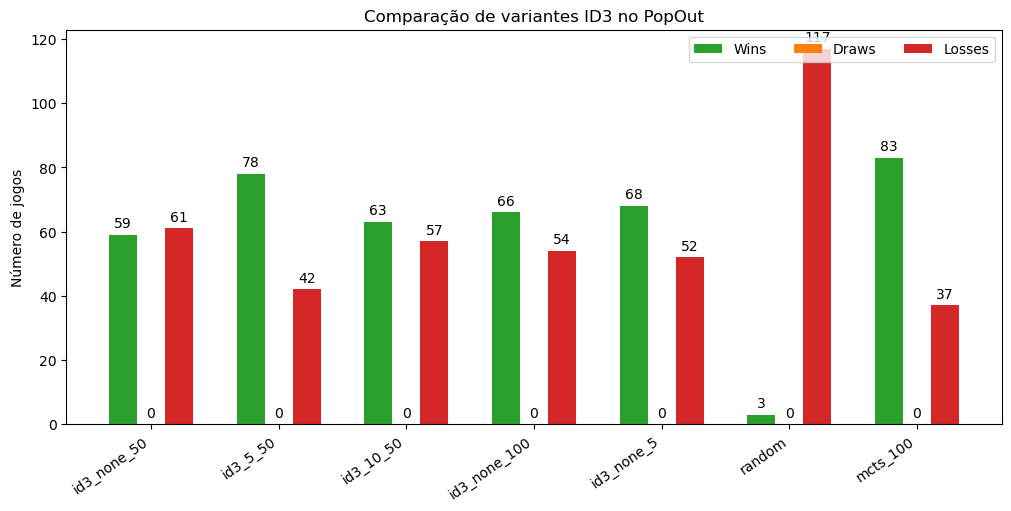

In [50]:
plot_bars_for_each_var(stats_game, "Comparação de variantes ID3 no PopOut")

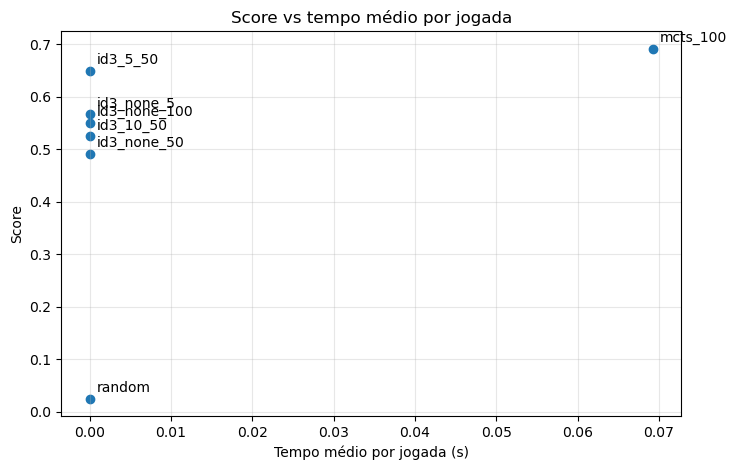

In [51]:
plot_score_vs_time(stats_game, "Score vs tempo médio por jogada")

### Discussão

Os resultados do torneio permitem comparar a correlação entre accuracy preditiva e performance real no jogo.

Observações esperadas:
- Os modelos ID3 com melhor accuracy (none/50, 5/50) devem apresentar score mais elevado.
- O `random` serve como baseline inferior — todos os ID3 devem superá-lo.
- O MCTS (com 100 iterações) deve ter o score mais alto, mas com tempo por jogada significativamente maior.
- O `predict_valid` suaviza diferenças: mesmo modelos fracos sobem na árvore até encontrar uma jogada válida, o que reduz o fosso entre eles.

Conclusão: a accuracy preditiva no dataset MCTS correlaciona-se positivamente com a performance no jogo, mas o `predict_valid` reduz o impacto das diferenças. O MCTS continua a ser o adversário mais forte, embora com custo computacional superior.